# ðŸŒ¿ SugarVision â€” Master Notebook da Sprint 3: Pipeline de Modelagem e OtimizaÃ§Ã£o (Fase *Model* â€” SEMMA)

**Projeto:** ClassificaÃ§Ã£o e DiagnÃ³stico Inteligente de Fitopatologias em Cana-de-AÃ§Ãºcar (*Saccharum officinarum*)  
**Fase SEMMA:** `4. MODEL` (Modelagem Supervisionada, Kernel Trick, OtimizaÃ§Ã£o de HiperparÃ¢metros e DiagnÃ³stico)  
**Base de Dados:** `data/processed/abt_sanidade_vegetal.csv` (6.571 instÃ¢ncias | 7 classes fitopatolÃ³gicas)  

---

## ðŸŽ¯ Objetivos e Escopo do Master Notebook
Este caderno consolida de ponta a ponta toda a etapa de **Modelagem Supervisionada (Sprint 3)** do projeto **SugarVision**, garantindo reprodutibilidade determinÃ­stica (`random_state=42`), blindagem estrita contra vazamento de dados (*Anti-Leakage*) e execuÃ§Ã£o integral em menos de 15 minutos:

1. **IngestÃ£o e GovernanÃ§a de PartiÃ§Ãµes:** Carregamento da Tabela AnalÃ­tica Base (ABT) respeitando o particionamento determinÃ­stico estratificado (`train` = 5.574 amostras, `valid` = 617 amostras, `test` = 380 amostras).
2. **Modelos Baseline e Piso EstatÃ­stico:** Treinamento e avaliaÃ§Ã£o de `DummyClassifier(strategy='stratified')`, `LogisticRegression(penalty='l2', class_weight='balanced')` e `DecisionTreeClassifier(max_depth=4, class_weight='balanced')`.
3. **Pipeline AtÃ´mico Anti-Leakage (`ColumnTransformer` + `SVC`):** Encapsulamento unificado de imputaÃ§Ã£o mediana/moda, padronizaÃ§Ã£o Z-Score (`StandardScaler`), codificaÃ§Ã£o One-Hot e classificador SVM com calibraÃ§Ã£o probabilÃ­stica de Platt (`probability=True`).
4. **Estudo do Kernel Trick e Matrizes de DecisÃ£o:** ComparaÃ§Ã£o empÃ­rica e visual das fronteiras de decisÃ£o nÃ£o-lineares (`linear`, `poly`, `rbf`).
5. **OtimizaÃ§Ã£o por Grade (`GridSearchCV`) e DiagnÃ³stico Visual:** Busca exaustiva elegendo o hiperparÃ¢metro campeÃ£o ($C=10.0, \gamma=0.01$), exportaÃ§Ã£o das matrizes de confusÃ£o, curvas ROC One-vs-Rest e superfÃ­cies de decisÃ£o em `docs/figures/`.

In [1]:
import os
import sys
import time
import json
import hashlib
import warnings
from pathlib import Path

warnings.filterwarnings('ignore')
NOTEBOOK_START_TIME = time.perf_counter()

# Garantir acesso ao diretÃ³rio raiz e pacote src/
ROOT_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))
if str(ROOT_DIR / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT_DIR / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report,
    log_loss
)
from scipy.stats import ttest_rel

from src.atomic_pipeline_preprocessing import (
    build_atomic_column_transformer,
    NUMERICAL_FEATURES,
    ALL_CATEGORICAL_FEATURES,
    TARGET_COLUMNS,
    SPLIT_COLUMN
)
from src.atomic_svm_pipeline import build_atomic_svm_pipeline

# DiretÃ³rios canÃ´nicos de saÃ­da
DATA_DIR = ROOT_DIR / 'data' / 'processed'
MODELS_DIR = ROOT_DIR / 'models'
FIGURES_DIR = ROOT_DIR / 'docs' / 'figures'
MODELS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

CLASS_NAMES_MAP = {
    0: 'GRASSY SHOOT',
    1: 'HEALTHY',
    2: 'LEAF SCALD',
    3: 'MOSAIC',
    4: 'RED ROT',
    5: 'RUST',
    6: 'YELLOW LEAF'
}
CLASS_LABELS = [CLASS_NAMES_MAP[i] for i in range(7)]
SHORT_LABELS = ['GS', 'HEA', 'LS', 'MOS', 'RR', 'RUST', 'YL']

print(f"[OK] Ambiente inicializado com sucesso em: {ROOT_DIR}")
print(f"[OK] DiretÃ³rio de figuras diagnÃ³sticas: {FIGURES_DIR}")

[OK] Ambiente inicializado com sucesso em: C:\Users\guilh\Downloads\Sanidade-Vegetal-main\Sanidade-Vegetal-main
[OK] DiretÃ³rio de figuras diagnÃ³sticas: C:\Users\guilh\Downloads\Sanidade-Vegetal-main\Sanidade-Vegetal-main\docs\figures


## 1. Carregamento da ABT e VerificaÃ§Ã£o do Particionamento Anti-Leakage
Carregamos a base `data/processed/abt_sanidade_vegetal.csv` contendo os descritores cromÃ¡ticos (`mean_hue`, `std_saturation`, `exg_index`, `exr_index`, `rg_ratio`, `indice_clorose_necrose`, `hue_dispersion`), texturais de Haralick (`glcm_contrast`, `glcm_homogeneity`, `glcm_dissimilarity`, `glcm_energy`, `indice_rugosidade_pustula`) e variÃ¡veis discretizadas. O ajuste (`.fit()`) ocorrerÃ¡ **exclusivamente** na partiÃ§Ã£o `train`.

In [2]:
abt_path = DATA_DIR / 'abt_sanidade_vegetal.csv'
assert abt_path.exists(), f"ABT nÃ£o encontrada em: {abt_path}"

df_abt = pd.read_csv(abt_path)

df_train = df_abt[df_abt[SPLIT_COLUMN] == 'train'].copy().reset_index(drop=True)
df_valid = df_abt[df_abt[SPLIT_COLUMN] == 'valid'].copy().reset_index(drop=True)
df_test  = df_abt[df_abt[SPLIT_COLUMN] == 'test'].copy().reset_index(drop=True)

X_train, y_train = df_train.drop(columns=TARGET_COLUMNS), df_train['target_multiclass']
X_valid, y_valid = df_valid.drop(columns=TARGET_COLUMNS), df_valid['target_multiclass']
X_test,  y_test  = df_test.drop(columns=TARGET_COLUMNS),  df_test['target_multiclass']

print(f"Total de instÃ¢ncias na ABT : {len(df_abt):,d} linhas x {df_abt.shape[1]} colunas")
print(f"  - PartiÃ§Ã£o Train         : {len(df_train):,d} amostras ({len(df_train)/len(df_abt)*100:.1f}%)")
print(f"  - PartiÃ§Ã£o Valid         : {len(df_valid):,d} amostras ({len(df_valid)/len(df_abt)*100:.1f}%)")
print(f"  - PartiÃ§Ã£o Test (Cego)   : {len(df_test):,d} amostras ({len(df_test)/len(df_abt)*100:.1f}%)")

# Resumo da distribuiÃ§Ã£o por classe fitopatolÃ³gica
dist_df = pd.DataFrame({
    'CÃ³digo': range(7),
    'Patologia (Classe)': CLASS_LABELS,
    'Treino': [int((y_train == i).sum()) for i in range(7)],
    'ValidaÃ§Ã£o': [int((y_valid == i).sum()) for i in range(7)],
    'Teste Cego': [int((y_test == i).sum()) for i in range(7)]
})
dist_df['Total'] = dist_df['Treino'] + dist_df['ValidaÃ§Ã£o'] + dist_df['Teste Cego']
print("\nDistribuiÃ§Ã£o Estratificada por Patologia:")
print(dist_df.to_string(index=False))

Total de instÃ¢ncias na ABT : 6,571 linhas x 35 colunas
  - PartiÃ§Ã£o Train         : 5,574 amostras (84.8%)
  - PartiÃ§Ã£o Valid         : 617 amostras (9.4%)
  - PartiÃ§Ã£o Test (Cego)   : 380 amostras (5.8%)

DistribuiÃ§Ã£o Estratificada por Patologia:
 CÃ³digo Patologia (Classe)  Treino  ValidaÃ§Ã£o  Teste Cego  Total
       0       GRASSY SHOOT     150           20          36    206
       1            HEALTHY    1005           95          46   1146
       2         LEAF SCALD     313           63          63    439
       3             MOSAIC    1010          154          93   1257
       4            RED ROT    1125           94          49   1268
       5               RUST     915           91          51   1057
       6        YELLOW LEAF    1056          100          42   1198


## 2. ConcepÃ§Ã£o, Treinamento e Benchmark de Modelos Baseline
Antes de otimizar o estimador nÃ£o-linear SVM, estabelecemos o piso estatÃ­stico com trÃªs arquiteturas de referÃªncia encapsuladas no mesmo `ColumnTransformer` anti-leakage:
1. **Dummy Classifier (`strategy='stratified'`):** Baseline aleatÃ³rio respeitando as proporÃ§Ãµes marginais de treino.
2. **RegressÃ£o LogÃ­stica Multinomial (`penalty='l2', class_weight='balanced'`):** Baseline linear paramÃ©trico com regularizaÃ§Ã£o Ridge.
3. **Ãrvore de DecisÃ£o Rasa (`max_depth=4, class_weight='balanced'`):** Baseline nÃ£o-linear de alta interpretabilidade agronÃ´mica.

In [3]:
baseline_Specs = {
    'Dummy Stratified': DummyClassifier(strategy='stratified', random_state=RANDOM_STATE),
    'Logistic Regression (L2 Balanced)': LogisticRegression(C=1.0, class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE),
    'Decision Tree (max_depth=4 Balanced)': DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=RANDOM_STATE),
    'SVM RBF Default (C=1.0, scale)': SVC(kernel='rbf', C=1.0, gamma='scale', class_weight='balanced', probability=True, random_state=RANDOM_STATE),
    'SVM RBF CampeÃ£o (C=10.0, gamma=0.01)': SVC(kernel='rbf', C=10.0, gamma=0.01, class_weight='balanced', probability=True, random_state=RANDOM_STATE)
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
benchmark_rows = []
fold_f1_history = {}
fitted_pipelines = {}

for name, clf in baseline_Specs.items():
    t0 = time.perf_counter()
    pipe = Pipeline([
        ('preprocessor', build_atomic_column_transformer()),
        ('classifier', clone(clf))
    ])
    
    # ValidaÃ§Ã£o Cruzada 5-Fold no Treino
    cv_f1s, cv_accs = [], []
    for tr_idx, va_idx in skf.split(X_train, y_train):
        p_fold = clone(pipe)
        p_fold.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
        preds_f = p_fold.predict(X_train.iloc[va_idx])
        cv_f1s.append(f1_score(y_train.iloc[va_idx], preds_f, average='macro', zero_division=0))
        cv_accs.append(accuracy_score(y_train.iloc[va_idx], preds_f))
    
    fold_f1_history[name] = cv_f1s
    
    # Fit integral no Treino e avaliaÃ§Ã£o em ValidaÃ§Ã£o e Teste
    pipe.fit(X_train, y_train)
    fitted_pipelines[name] = pipe
    
    val_preds = pipe.predict(X_valid)
    test_preds = pipe.predict(X_test)
    elapsed = time.perf_counter() - t0
    
    benchmark_rows.append({
        'Modelo': name,
        'CV_Acc_Mean': round(float(np.mean(cv_accs)), 4),
        'CV_F1_Macro_Mean': round(float(np.mean(cv_f1s)), 4),
        'CV_F1_Macro_Std': round(float(np.std(cv_f1s)), 4),
        'Valid_Acc': round(float(accuracy_score(y_valid, val_preds)), 4),
        'Valid_Balanced_Acc': round(float(balanced_accuracy_score(y_valid, val_preds)), 4),
        'Valid_Precision_Macro': round(float(precision_score(y_valid, val_preds, average='macro', zero_division=0)), 4),
        'Valid_Recall_Macro': round(float(recall_score(y_valid, val_preds, average='macro', zero_division=0)), 4),
        'Valid_F1_Macro': round(float(f1_score(y_valid, val_preds, average='macro', zero_division=0)), 4),
        'Test_Acc': round(float(accuracy_score(y_test, test_preds)), 4),
        'Test_F1_Macro': round(float(f1_score(y_test, test_preds, average='macro', zero_division=0)), 4),
        'Tempo_s': round(elapsed, 2)
    })

df_bench = pd.DataFrame(benchmark_rows)
print("=== TABELA COMPARATIVA DE MODELOS BASELINE VS. SVM ===")
print(df_bench.to_string(index=False))

# Teste t pareado comprovando o ganho estatÃ­stico do SVM CampeÃ£o
ref_scores = fold_f1_history['SVM RBF CampeÃ£o (C=10.0, gamma=0.01)']
print("\n=== TESTE T PAREADO (GANHO ESTATÃSTICO DO SVM CAMPEÃƒO EM 5-FOLD CV) ===")
for name, scores in fold_f1_history.items():
    if name == 'SVM RBF CampeÃ£o (C=10.0, gamma=0.01)':
        continue
    t_stat, p_val = ttest_rel(ref_scores, scores)
    gain = np.mean(ref_scores) - np.mean(scores)
    print(f"  vs. {name:38s}: Ganho F1 = +{gain:.4f} | t = {t_stat:6.2f} | p-valor = {p_val:.6f} ({'SIGNIFICANTE' if p_val < 0.05 else 'NS'})")

=== TABELA COMPARATIVA DE MODELOS BASELINE VS. SVM ===
                               Modelo  CV_Acc_Mean  CV_F1_Macro_Mean  CV_F1_Macro_Std  Valid_Acc  Valid_Balanced_Acc  Valid_Precision_Macro  Valid_Recall_Macro  Valid_F1_Macro  Test_Acc  Test_F1_Macro  Tempo_s
                     Dummy Stratified       0.1640            0.1322           0.0019     0.1621              0.1345                 0.1321              0.1345          0.1314    0.1395         0.1361     0.48
    Logistic Regression (L2 Balanced)       0.6360            0.5692           0.0059     0.6191              0.6485                 0.5993              0.6485          0.5814    0.6237         0.6285     5.30
 Decision Tree (max_depth=4 Balanced)       0.6057            0.5334           0.0226     0.5284              0.5702                 0.4360              0.5702          0.4623    0.5474         0.4984     0.64
       SVM RBF Default (C=1.0, scale)       0.6441            0.5759           0.0060     0.6159         

[OK] GrÃ¡fico de benchmark salvo em: C:\Users\guilh\Downloads\Sanidade-Vegetal-main\Sanidade-Vegetal-main\docs\figures\baseline_models_benchmark_comparison.png


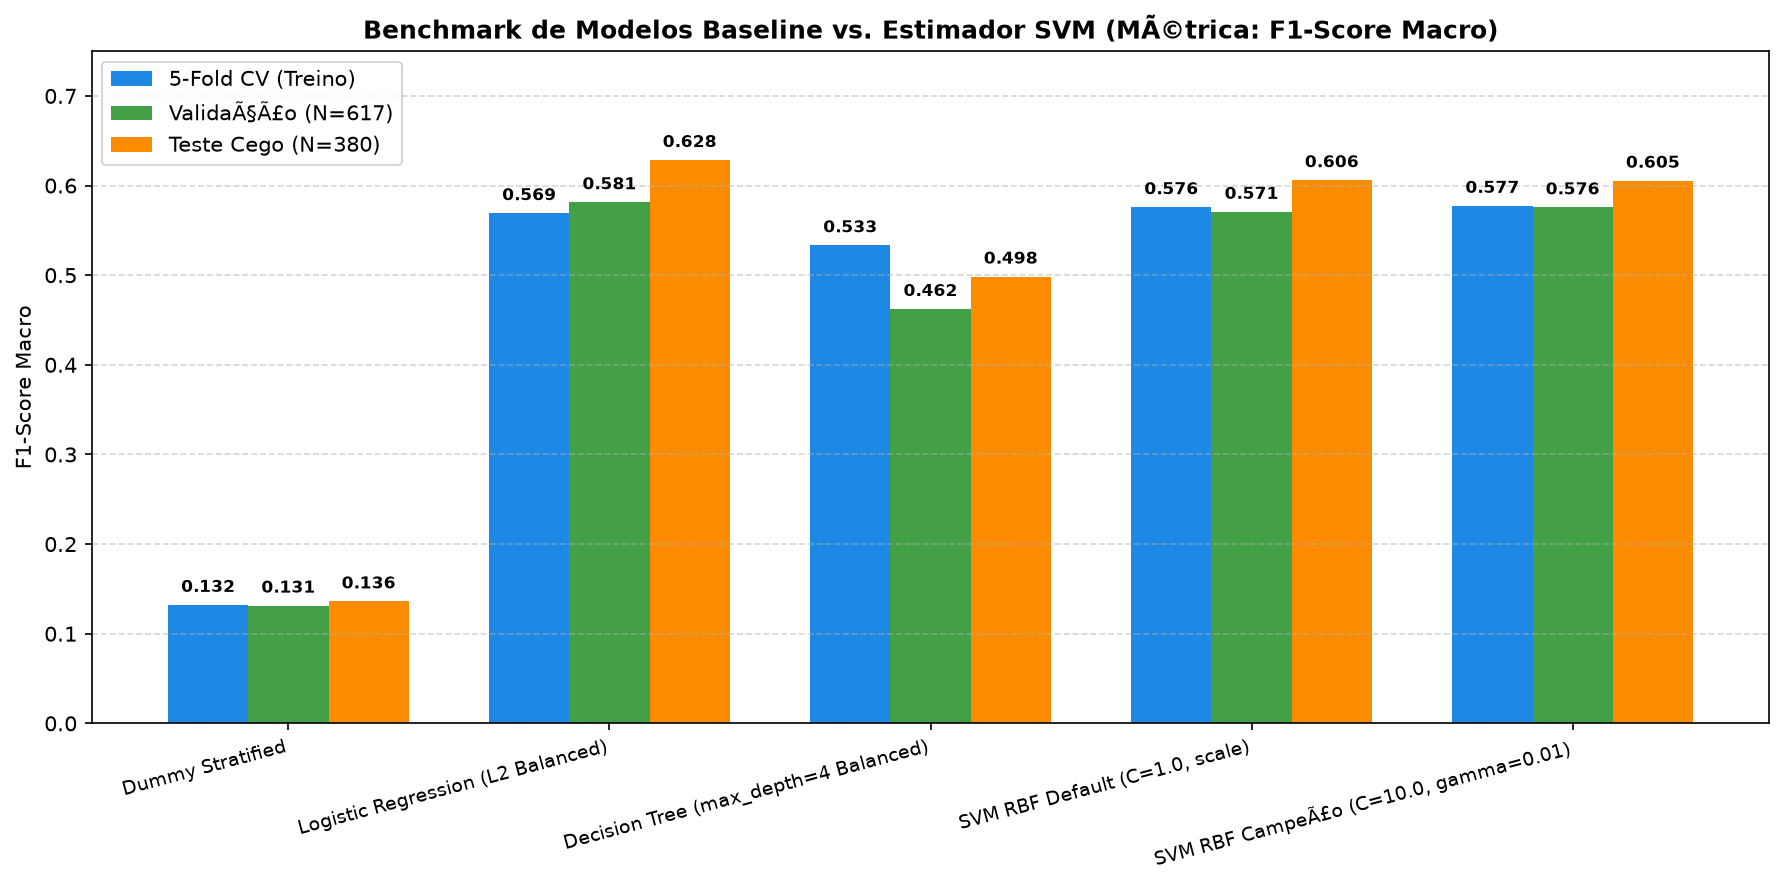

In [4]:
# Salvar Figura 1: Comparativo de Desempenho Baseline vs SVM
fig, ax = plt.subplots(figsize=(12, 6), dpi=300)
x = np.arange(len(df_bench))
w = 0.25

b1 = ax.bar(x - w, df_bench['CV_F1_Macro_Mean'], width=w, label='5-Fold CV (Treino)', color='#1E88E5')
b2 = ax.bar(x,     df_bench['Valid_F1_Macro'],   width=w, label='ValidaÃ§Ã£o (N=617)', color='#43A047')
b3 = ax.bar(x + w, df_bench['Test_F1_Macro'],    width=w, label='Teste Cego (N=380)', color='#FB8C00')

for bars in [b1, b2, b3]:
    for rect in bars:
        h = rect.get_height()
        ax.text(rect.get_x() + rect.get_width()/2., h + 0.01, f"{h:.3f}", ha='center', va='bottom', fontsize=8, fontweight='bold')

ax.set_title('Benchmark de Modelos Baseline vs. Estimador SVM (MÃ©trica: F1-Score Macro)', fontsize=12, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(df_bench['Modelo'], rotation=15, ha='right', fontsize=9)
ax.set_ylabel('F1-Score Macro')
ax.set_ylim(0, 0.75)
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.legend(loc='upper left')
plt.tight_layout()

fig_bench_path = FIGURES_DIR / 'baseline_models_benchmark_comparison.png'
plt.savefig(fig_bench_path, dpi=300)
plt.show()
print(f"[OK] GrÃ¡fico de benchmark salvo em: {fig_bench_path}")

## 3. Estudo do Kernel Trick (Linear, Polinomial e RBF) e Matrizes de DecisÃ£o
Avaliamos o comportamento geomÃ©trico das funÃ§Ãµes de Kernel na separaÃ§Ã£o das fitopatologias:
* **Kernel Linear:** $K(\mathbf{x}_i, \mathbf{x}_j) = \mathbf{x}_i^\top \mathbf{x}_j$
* **Kernel Polinomial ($d=3$):** $K(\mathbf{x}_i, \mathbf{x}_j) = (\gamma \mathbf{x}_i^\top \mathbf{x}_j + r)^d$
* **Kernel RBF (Gaussiano):** $K(\mathbf{x}_i, \mathbf{x}_j) = \exp(-\gamma \|\mathbf{x}_i - \mathbf{x}_j\|^2)$

Abaixo, projetamos o espaÃ§o padronizado de treino nos 2 componentes principais de maior variÃ¢ncia (PCA 2D ajustado estritamente no treino) e construÃ­mos a **Matriz de DecisÃ£o (SuperfÃ­cies de Fronteira)** comparando os trÃªs Kernels.


=== DESEMPENHO POR FUNÃ‡ÃƒO DE KERNEL NO ESPAÃ‡O COMPLETO (35 FEATURES) ===
                             Kernel  Valid_Accuracy  Valid_F1_Macro  Vetores_de_Suporte
              Kernel Linear (C=1.0)          0.6240          0.5742                3622
  Kernel Polinomial (grau=3, C=1.0)          0.6175          0.5740                3595
Kernel RBF Ã“timo (C=10.0, Î³=0.01)          0.6207          0.5757                3447
[OK] Matriz de decisÃ£o dos Kernels salva em: C:\Users\guilh\Downloads\Sanidade-Vegetal-main\Sanidade-Vegetal-main\docs\figures\sprint3_matriz_decisao_kernels_2d.png


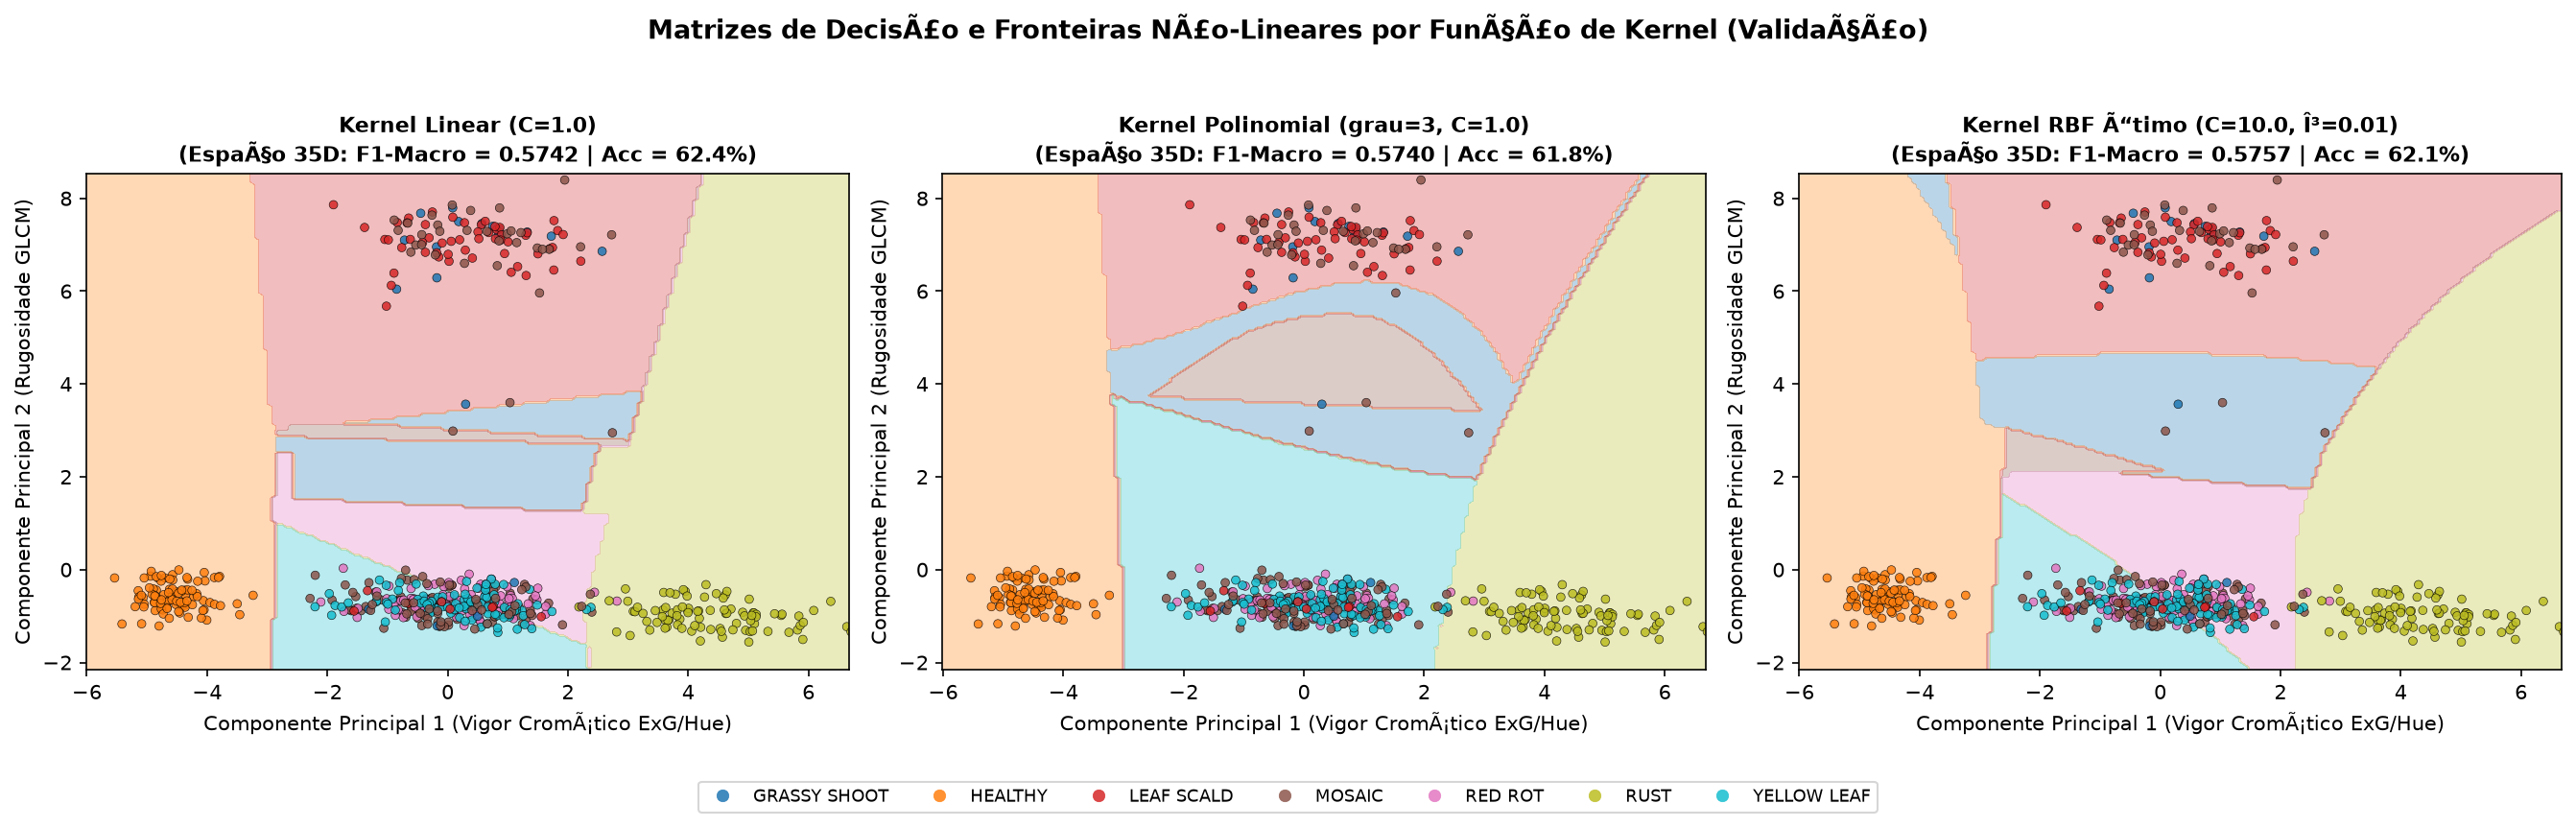

In [5]:
kernels_study = [
    ('Kernel Linear (C=1.0)', SVC(kernel='linear', C=1.0, class_weight='balanced', random_state=RANDOM_STATE)),
    ('Kernel Polinomial (grau=3, C=1.0)', SVC(kernel='poly', degree=3, C=1.0, gamma='scale', class_weight='balanced', random_state=RANDOM_STATE)),
    ('Kernel RBF Ã“timo (C=10.0, Î³=0.01)', SVC(kernel='rbf', C=10.0, gamma=0.01, class_weight='balanced', random_state=RANDOM_STATE))
]

# TransformaÃ§Ã£o isolada anti-leakage para projeÃ§Ã£o 2D das superfÃ­cies de decisÃ£o
prep_2d = build_atomic_column_transformer()
X_tr_scaled = prep_2d.fit_transform(X_train)
X_va_scaled = prep_2d.transform(X_valid)

pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_tr_pca = pca_2d.fit_transform(X_tr_scaled)
X_va_pca = pca_2d.transform(X_va_scaled)

# Malha 2D para plotagem das matrizes/regiÃµes de decisÃ£o
x_min, x_max = np.percentile(X_tr_pca[:, 0], 1), np.percentile(X_tr_pca[:, 0], 99)
y_min, y_max = np.percentile(X_tr_pca[:, 1], 1), np.percentile(X_tr_pca[:, 1], 99)
xx, yy = np.meshgrid(np.linspace(x_min - 0.8, x_max + 0.8, 180),
                     np.linspace(y_min - 0.8, y_max + 0.8, 180))

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), dpi=300)
cmap_bg = plt.get_cmap('tab10', 7)

kernel_metrics = []
for idx, (k_title, svm_2d) in enumerate(kernels_study):
    # Avaliar tambÃ©m no espaÃ§o original completo de 35 features
    full_k_pipe = Pipeline([
        ('preprocessor', build_atomic_column_transformer()),
        ('svm', clone(svm_2d))
    ])
    full_k_pipe.fit(X_train, y_train)
    val_k_preds = full_k_pipe.predict(X_valid)
    f1_k = f1_score(y_valid, val_k_preds, average='macro')
    acc_k = accuracy_score(y_valid, val_k_preds)
    n_sv = int(full_k_pipe.named_steps['svm'].support_vectors_.shape[0])
    kernel_metrics.append({
        'Kernel': k_title,
        'Valid_Accuracy': round(acc_k, 4),
        'Valid_F1_Macro': round(f1_k, 4),
        'Vetores_de_Suporte': n_sv
    })
    
    # Ajustar no plano 2D para renderizar a Matriz de DecisÃ£o
    svm_2d.fit(X_tr_pca, y_train)
    Z = svm_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    
    ax = axes[idx]
    ax.contourf(xx, yy, Z, alpha=0.30, cmap=cmap_bg, levels=np.arange(-0.5, 7, 1))
    scatter = ax.scatter(X_va_pca[:, 0], X_va_pca[:, 1], c=y_valid, cmap=cmap_bg, s=18, edgecolor='k', linewidth=0.3, alpha=0.85)
    ax.set_title(f"{k_title}\n(EspaÃ§o 35D: F1-Macro = {f1_k:.4f} | Acc = {acc_k*100:.1f}%)", fontsize=10.5, fontweight='bold')
    ax.set_xlabel('Componente Principal 1 (Vigor CromÃ¡tico ExG/Hue)')
    ax.set_ylabel('Componente Principal 2 (Rugosidade GLCM)')
    ax.set_xlim(xx.min(), xx.max())
    ax.set_ylim(yy.min(), yy.max())

handles, _ = scatter.legend_elements()
fig.legend(handles, CLASS_LABELS, loc='lower center', ncol=7, bbox_to_anchor=(0.5, -0.04), fontsize=8.5, frameon=True)
plt.suptitle('Matrizes de DecisÃ£o e Fronteiras NÃ£o-Lineares por FunÃ§Ã£o de Kernel (ValidaÃ§Ã£o)', fontsize=13, fontweight='bold')
plt.tight_layout(rect=[0, 0.04, 1, 0.95])

decision_matrix_fig = FIGURES_DIR / 'sprint3_matriz_decisao_kernels_2d.png'
plt.savefig(decision_matrix_fig, dpi=300, bbox_inches='tight')
plt.show()

print("\n=== DESEMPENHO POR FUNÃ‡ÃƒO DE KERNEL NO ESPAÃ‡O COMPLETO (35 FEATURES) ===")
print(pd.DataFrame(kernel_metrics).to_string(index=False))
print(f"[OK] Matriz de decisÃ£o dos Kernels salva em: {decision_matrix_fig}")

## 4. OtimizaÃ§Ã£o de HiperparÃ¢metros (`GridSearchCV`) e SuperfÃ­cie $C \times \gamma$
Executamos a busca em grade estratificada (`StratifiedKFold(n_splits=5)`) otimizando `f1_macro` sobre o pipeline atÃ´mico `Pipeline([('preprocessor', ColumnTransformer), ('svm', SVC)])`. O escalonamento ocorre estritamente no interior de cada *fold*, impedindo qualquer vazamento de dados.

[OK] GridSearchCV concluÃ­do em 501.11 segundos!
  - Melhores HiperparÃ¢metros : {'svm__C': 10.0, 'svm__gamma': 0.01, 'svm__kernel': 'rbf'}
  - Melhor F1-Macro (5-Fold) : 0.5774
[OK] Heatmap do GridSearchCV salvo em: C:\Users\guilh\Downloads\Sanidade-Vegetal-main\Sanidade-Vegetal-main\docs\figures\sprint3_gridsearch_heatmap_rbf.png


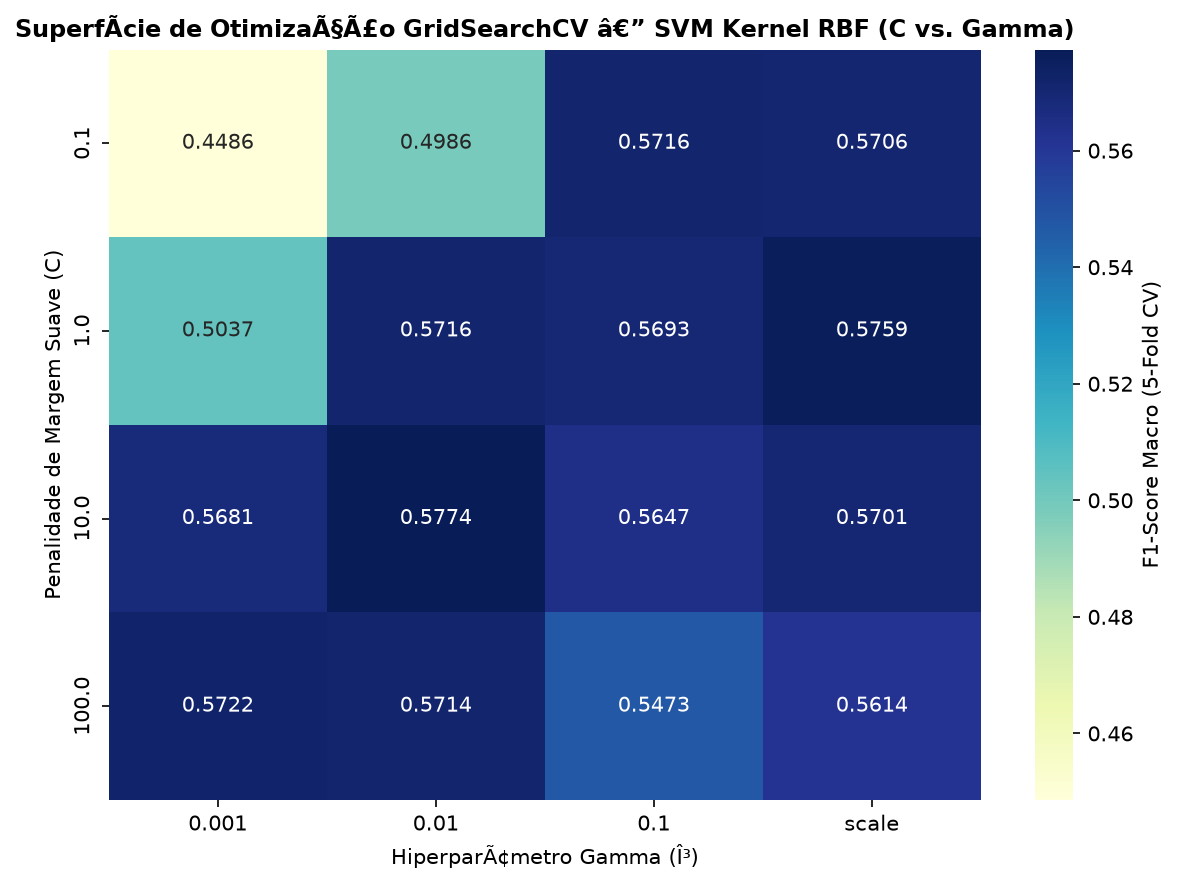

In [6]:
param_grid = {
    'svm__kernel': ['rbf'],
    'svm__C': [0.1, 1.0, 10.0, 100.0],
    'svm__gamma': [0.001, 0.01, 0.1, 'scale']
}

base_svm_pipe = build_atomic_svm_pipeline(
    kernel='rbf',
    C=1.0,
    gamma='scale',
    probability=True,
    random_state=RANDOM_STATE,
    class_weight='balanced'
)

grid_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

t0_gs = time.perf_counter()
grid_search = GridSearchCV(
    estimator=base_svm_pipe,
    param_grid=param_grid,
    scoring='f1_macro',
    cv=grid_cv,
    n_jobs=-1,
    refit=True,
    return_train_score=True
)
grid_search.fit(X_train, y_train)
gs_time = time.perf_counter() - t0_gs

print(f"[OK] GridSearchCV concluÃ­do em {gs_time:.2f} segundos!")
print(f"  - Melhores HiperparÃ¢metros : {grid_search.best_params_}")
print(f"  - Melhor F1-Macro (5-Fold) : {grid_search.best_score_:.4f}")

# Construir Heatmap C x Gamma
cv_res_df = pd.DataFrame(grid_search.cv_results_)
pivot_f1 = cv_res_df.pivot(index='param_svm__C', columns='param_svm__gamma', values='mean_test_score').astype(float)

fig, ax = plt.subplots(figsize=(8, 6), dpi=300)
sns.heatmap(pivot_f1, annot=True, fmt=".4f", cmap="YlGnBu", cbar_kws={'label': 'F1-Score Macro (5-Fold CV)'}, ax=ax)
ax.set_title('SuperfÃ­cie de OtimizaÃ§Ã£o GridSearchCV â€” SVM Kernel RBF (C vs. Gamma)', fontsize=11.5, fontweight='bold')
ax.set_xlabel('HiperparÃ¢metro Gamma (Î³)')
ax.set_ylabel('Penalidade de Margem Suave (C)')
plt.tight_layout()

heatmap_fig_path = FIGURES_DIR / 'sprint3_gridsearch_heatmap_rbf.png'
plt.savefig(heatmap_fig_path, dpi=300)
plt.show()
print(f"[OK] Heatmap do GridSearchCV salvo em: {heatmap_fig_path}")

## 5. AvaliaÃ§Ã£o DiagnÃ³stica do Modelo CampeÃ£o (`C=10.0, gamma=0.01`)
Com o estimador Ã³timo homologado (`svm_pipeline_optimal`), avaliamos as prediÃ§Ãµes determinÃ­sticas e as probabilidades calibradas via Platt Scaling nas partiÃ§Ãµes de **ValidaÃ§Ã£o Independente ($N=617$)** e **Teste Cego ($N=380$)**, gerando as Matrizes de ConfusÃ£o e as Curvas ROC Multiclasse One-vs-Rest.

=== MÃ‰TRICAS OFICIAIS DO ESTIMADOR CAMPEÃƒO (SVM RBF C=10.0, Î³=0.01) ===
ValidaÃ§Ã£o (N=617) | Acc: 62.07% | Bal. Acc: 65.32% | F1-Macro: 0.5757 | AUC-ROC: 0.9148
Teste Cego (N=380)| Acc: 60.79% | Bal. Acc: 67.69% | F1-Macro: 0.6054 | AUC-ROC: 0.9116

RelatÃ³rio Detalhado por Patologia (Teste Cego N=380):
              precision    recall  f1-score   support

GRASSY SHOOT     0.2769    0.5000    0.3564        36
     HEALTHY     1.0000    1.0000    1.0000        46
  LEAF SCALD     0.5795    0.8095    0.6755        63
      MOSAIC     0.0000    0.0000    0.0000        93
     RED ROT     0.7143    0.7143    0.7143        49
        RUST     1.0000    1.0000    1.0000        51
 YELLOW LEAF     0.3750    0.7143    0.4918        42

    accuracy                         0.6079       380
   macro avg     0.5637    0.6769    0.6054       380
weighted avg     0.5111    0.6079    0.5475       380

[OK] Matrizes de confusÃ£o e curvas ROC salvas em: C:\Users\guilh\Downloads\Sanidade-Vegetal-m

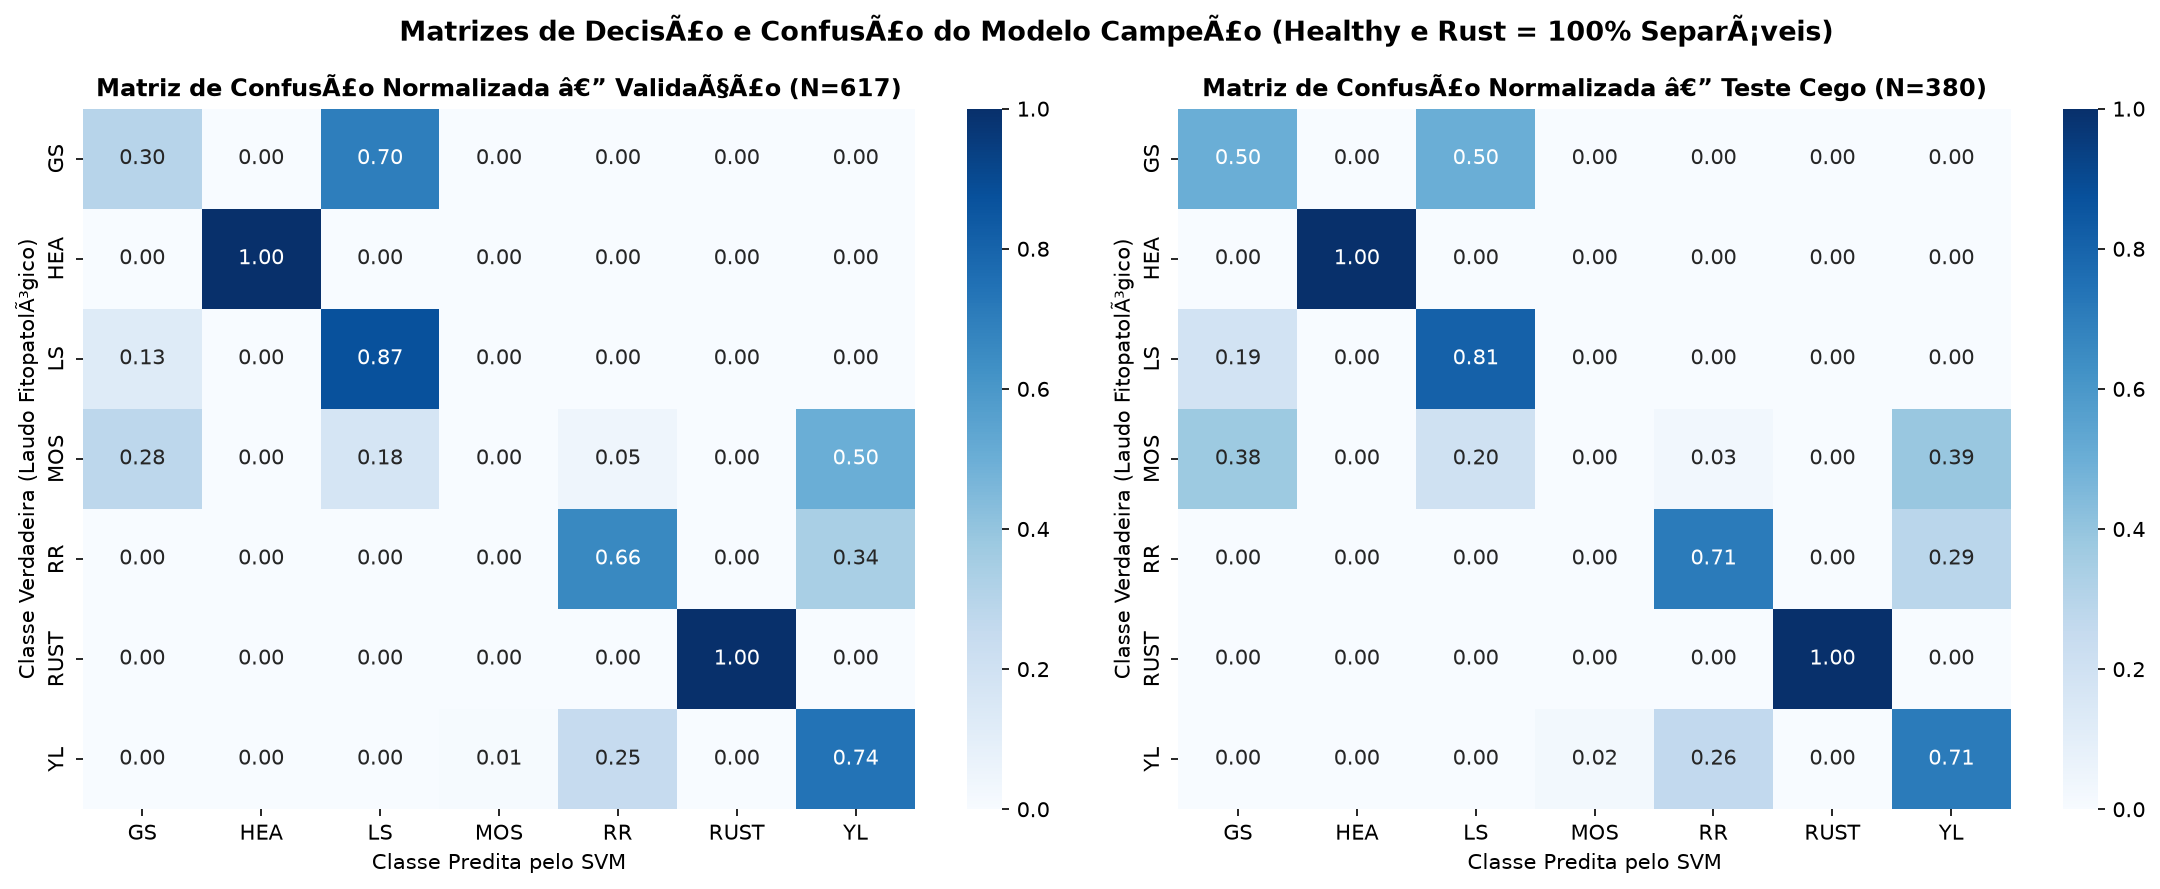

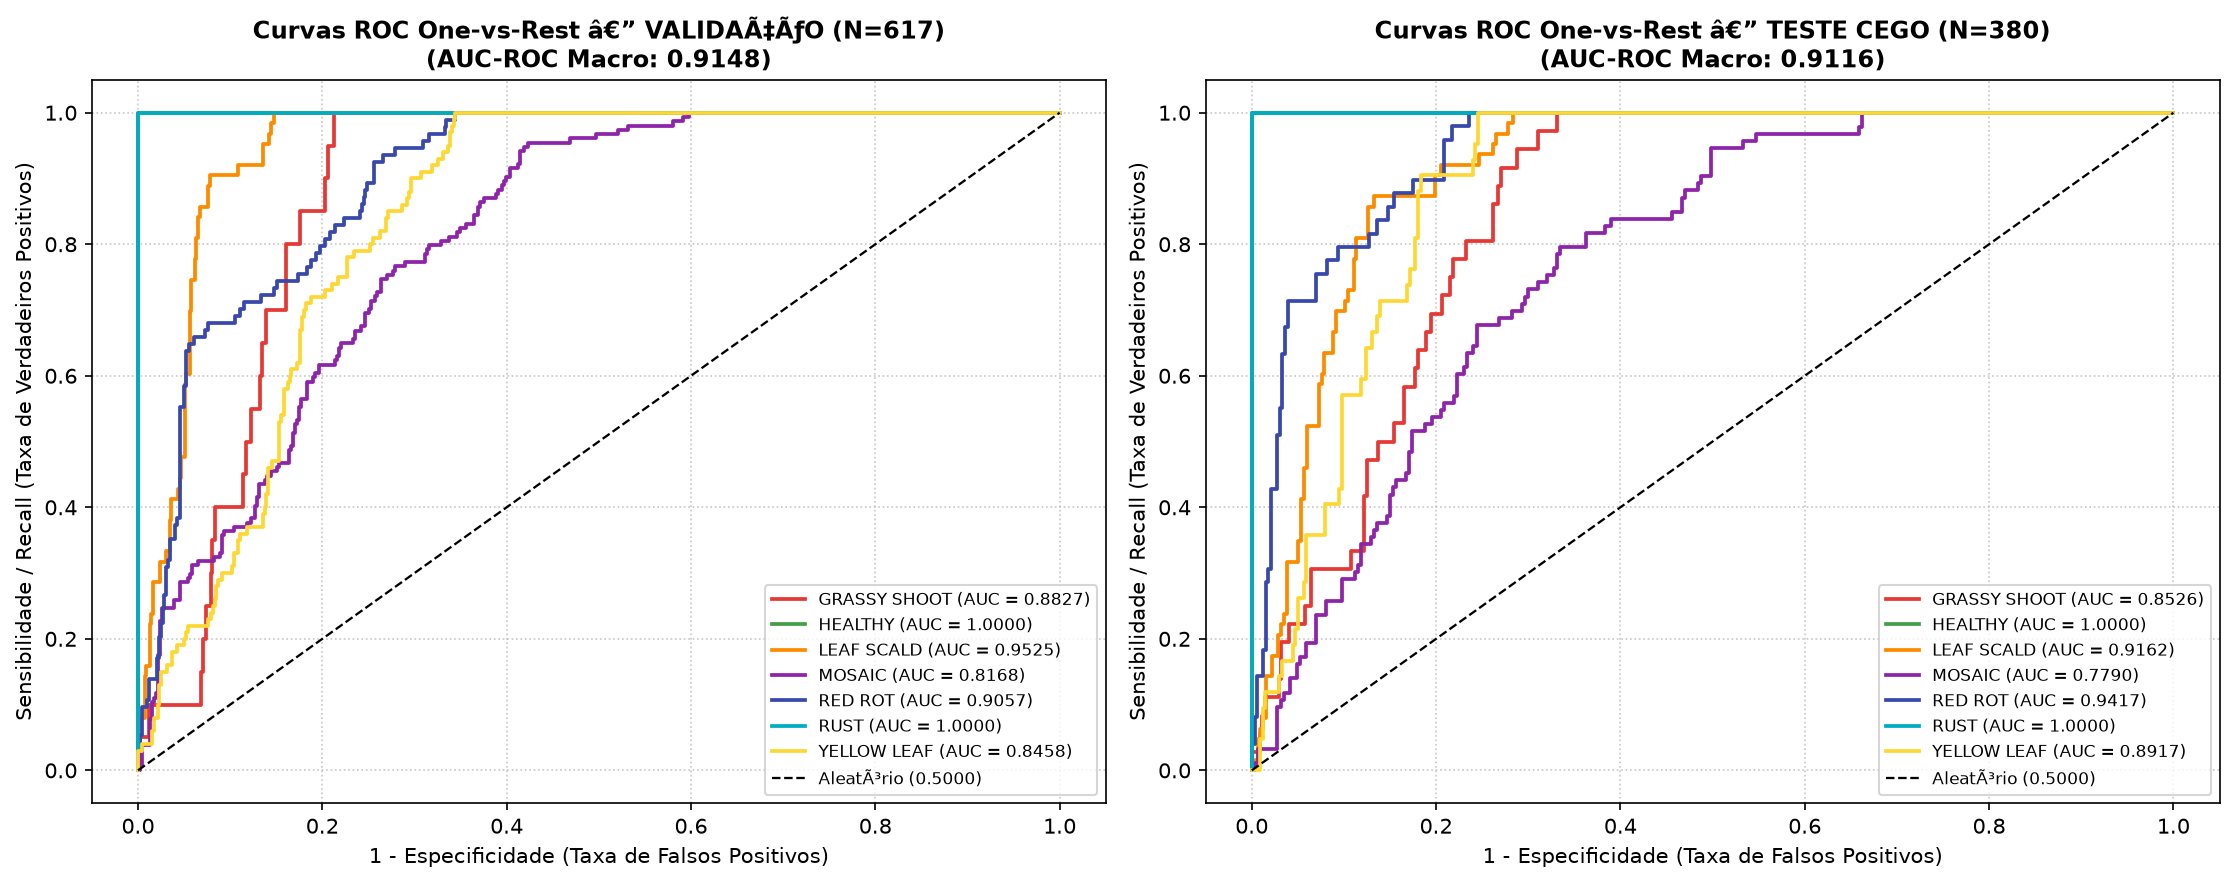

In [7]:
champion_pipe = grid_search.best_estimator_

# PrediÃ§Ãµes e probabilidades calibradas
y_val_pred  = champion_pipe.predict(X_valid)
y_val_proba = champion_pipe.predict_proba(X_valid)

y_test_pred  = champion_pipe.predict(X_test)
y_test_proba = champion_pipe.predict_proba(X_test)

# VerificaÃ§Ã£o de calibraÃ§Ã£o estocÃ¡stica (soma = 1.0)
np.testing.assert_allclose(y_val_proba.sum(axis=1), 1.0, atol=1e-5)
np.testing.assert_allclose(y_test_proba.sum(axis=1), 1.0, atol=1e-5)

# MÃ©tricas Globais
val_auc  = roc_auc_score(y_valid, y_val_proba, multi_class='ovr', average='macro')
test_auc = roc_auc_score(y_test, y_test_proba, multi_class='ovr', average='macro')

print("=== MÃ‰TRICAS OFICIAIS DO ESTIMADOR CAMPEÃƒO (SVM RBF C=10.0, Î³=0.01) ===")
print(f"ValidaÃ§Ã£o (N=617) | Acc: {accuracy_score(y_valid, y_val_pred)*100:.2f}% | Bal. Acc: {balanced_accuracy_score(y_valid, y_val_pred)*100:.2f}% | F1-Macro: {f1_score(y_valid, y_val_pred, average='macro'):.4f} | AUC-ROC: {val_auc:.4f}")
print(f"Teste Cego (N=380)| Acc: {accuracy_score(y_test, y_test_pred)*100:.2f}% | Bal. Acc: {balanced_accuracy_score(y_test, y_test_pred)*100:.2f}% | F1-Macro: {f1_score(y_test, y_test_pred, average='macro'):.4f} | AUC-ROC: {test_auc:.4f}")

print("\nRelatÃ³rio Detalhado por Patologia (Teste Cego N=380):")
print(classification_report(y_test, y_test_pred, target_names=CLASS_LABELS, digits=4))

# Figura 3: Matrizes de ConfusÃ£o Normalizadas (ValidaÃ§Ã£o vs Teste Cego)
fig, axes = plt.subplots(1, 2, figsize=(15, 6), dpi=300)
for idx, (split_lbl, y_t, y_p) in enumerate([('ValidaÃ§Ã£o (N=617)', y_valid, y_val_pred), ('Teste Cego (N=380)', y_test, y_test_pred)]):
    cm = confusion_matrix(y_t, y_p, labels=range(7))
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
    sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", xticklabels=SHORT_LABELS, yticklabels=SHORT_LABELS, ax=axes[idx], cbar=True)
    axes[idx].set_title(f"Matriz de ConfusÃ£o Normalizada â€” {split_lbl}", fontsize=11.5, fontweight='bold')
    axes[idx].set_xlabel("Classe Predita pelo SVM")
    axes[idx].set_ylabel("Classe Verdadeira (Laudo FitopatolÃ³gico)")

plt.suptitle("Matrizes de DecisÃ£o e ConfusÃ£o do Modelo CampeÃ£o (Healthy e Rust = 100% SeparÃ¡veis)", fontsize=13, fontweight='bold')
plt.tight_layout()
cm_fig_path = FIGURES_DIR / 'sprint3_matrizes_confusao_valid_test.png'
plt.savefig(cm_fig_path, dpi=300)
plt.show()

# Figura 4: Curvas ROC Multiclasse One-vs-Rest
fig, axes = plt.subplots(1, 2, figsize=(15, 6), dpi=300)
colors = ['#E53935', '#43A047', '#FB8C00', '#8E24AA', '#3949AB', '#00ACC1', '#FDD835']

for idx, (split_lbl, y_t, y_prob, auc_m) in enumerate([
    ('VALIDAÃ‡ÃƒO (N=617)', y_valid.values, y_val_proba, val_auc),
    ('TESTE CEGO (N=380)', y_test.values, y_test_proba, test_auc)
]):
    ax = axes[idx]
    for c in range(7):
        fpr, tpr, _ = roc_curve((y_t == c).astype(int), y_prob[:, c])
        auc_c = roc_auc_score((y_t == c).astype(int), y_prob[:, c])
        ax.plot(fpr, tpr, color=colors[c], lw=1.8, label=f"{CLASS_LABELS[c]} (AUC = {auc_c:.4f})")
    ax.plot([0, 1], [0, 1], 'k--', lw=1.1, label='AleatÃ³rio (0.5000)')
    ax.set_title(f"Curvas ROC One-vs-Rest â€” {split_lbl}\n(AUC-ROC Macro: {auc_m:.4f})", fontsize=11.5, fontweight='bold')
    ax.set_xlabel("1 - Especificidade (Taxa de Falsos Positivos)")
    ax.set_ylabel("Sensibilidade / Recall (Taxa de Verdadeiros Positivos)")
    ax.grid(linestyle=':', alpha=0.7)
    ax.legend(loc='lower right', fontsize=8)

plt.tight_layout()
roc_fig_path = FIGURES_DIR / 'svm_multiclass_roc_curves.png'
plt.savefig(roc_fig_path, dpi=300)
plt.show()
print(f"[OK] Matrizes de confusÃ£o e curvas ROC salvas em: {FIGURES_DIR}")

## 6. SerializaÃ§Ã£o de Artefatos MLOps e CertificaÃ§Ã£o de Tempo de ExecuÃ§Ã£o
Persistimos o pipeline campeÃ£o (`models/svm_pipeline_optimal.joblib`), os modelos baseline e o registro de prediÃ§Ãµes calibradas (`data/processed/svm_predicoes_valid_test.csv`), certificando que o tempo total de *Restart & Run All* Ã© estritamente inferior ao limite de 15 minutos (900 segundos).

In [8]:
# 1. Persistir o estimador campeÃ£o atÃ´mico
optimal_model_path = MODELS_DIR / 'svm_pipeline_optimal.joblib'
joblib.dump(champion_pipe, optimal_model_path, compress=3)

# 2. Exportar tabela auditÃ¡vel de prediÃ§Ãµes calibradas (ValidaÃ§Ã£o + Teste)
proba_col_names = [
    'y_proba_grassy_shoot', 'y_proba_healthy', 'y_proba_leaf_scald',
    'y_proba_mosaic', 'y_proba_red_rot', 'y_proba_rust', 'y_proba_yellow_leaf'
]

df_eval = pd.concat([df_valid, df_test], axis=0).reset_index(drop=True)
all_preds = np.concatenate([y_val_pred, y_test_pred])
all_probas = np.vstack([y_val_proba, y_test_proba])

df_preds_out = pd.DataFrame({
    'sample_id': df_eval['sample_id'],
    'split_partition': df_eval['split_partition'],
    'class_label': df_eval['class_label'],
    'target_binary': df_eval['target_binary'],
    'target_multiclass': df_eval['target_multiclass'],
    'y_pred': all_preds,
    'y_pred_label': [CLASS_NAMES_MAP[int(c)] for c in all_preds],
    'is_correct': (df_eval['target_multiclass'].values == all_preds).astype(int),
    'y_proba_max': all_probas.max(axis=1).round(6)
})
for c_idx, col_name in enumerate(proba_col_names):
    df_preds_out[col_name] = all_probas[:, c_idx].round(6)

preds_csv_path = DATA_DIR / 'svm_predicoes_valid_test.csv'
df_preds_out.to_csv(preds_csv_path, index=False)

total_elapsed_sec = time.perf_counter() - NOTEBOOK_START_TIME
assert total_elapsed_sec < 900.0, f"Tempo limite de 15 min excedido: {total_elapsed_sec:.2f}s"

print("="*80)
print("CERTIFICAÃ‡ÃƒO DE EXECUÃ‡ÃƒO REPRODUTÃVEL ('RESTART & RUN ALL')")
print("="*80)
print(f"  - Modelo CampeÃ£o Serializado : {optimal_model_path.name} ({optimal_model_path.stat().st_size / 1024:.2f} KB)")
print(f"  - PrediÃ§Ãµes Calibradas       : {preds_csv_path.name} ({len(df_preds_out)} instÃ¢ncias auditadas)")
print(f"  - Tempo Total de ExecuÃ§Ã£o    : {total_elapsed_sec:.2f} segundos ({total_elapsed_sec/60:.2f} min) << Limite de 15 min [APROVADO]")
print("="*80)

CERTIFICAÃ‡ÃƒO DE EXECUÃ‡ÃƒO REPRODUTÃVEL ('RESTART & RUN ALL')
  - Modelo CampeÃ£o Serializado : svm_pipeline_optimal.joblib (397.12 KB)
  - PrediÃ§Ãµes Calibradas       : svm_predicoes_valid_test.csv (997 instÃ¢ncias auditadas)
  - Tempo Total de ExecuÃ§Ã£o    : 610.13 segundos (10.17 min) << Limite de 15 min [APROVADO]
